# Entrega 3 · ¿La imagen aporta a la predicción del mRS al egreso?

**Objetivo:** predecir el mal desenlace al egreso (mRS > 2) en ACV isquémico combinando RM DWI/ADC con variables clínicas, y saber si la imagen aporta más allá de la clínica.

Este notebook reproduce los resultados de la Entrega 3. Corre de arriba abajo:

| Celda | Qué hace | Script |
|---|---|---|
| [1] | Configuración y rutas | — |
| [2] | Tabla limpia: AUC antes y después de la auditoría | `07_tabla_limpia/evaluar.py` |
| [3] | Controles de la fusión (corrida completa de Kaggle) | `resultados_acv_p/resumen.csv` |
| [4] | Ubicación de la lesión | `06_mapa_lesiones/` |
| [5] | Desconexión con el atlas JHU | `08_desconexion/desconexion.py` |
| [6] | Tractotron (68 tractos) + `dataset_report.csv` | `09_tractotron/` |
| [7] | Síntesis: cambio de AUC frente a edad + NIHSS | — |

**Datos:** la cohorte FOSCAL es privada (acuerdo de ética y uso de datos) y no está en el repositorio. Las rutas de la celda [1] apuntan a la carpeta superior al repositorio. Todas las salidas son agregadas: ninguna celda imprime identificadores de pacientes ni imágenes individuales.

In [1]:
# [1] Configuración y rutas
import os, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

REPO = Path.cwd()                      # carpeta text/ (raíz del repositorio)
DATOS = REPO.parent                    # carpeta con acv_split/, dataset_report.csv, logTractotron.txt
RESUMEN = Path(os.environ.get("ACV_RESUMEN", DATOS.parent / "resultados_acv_p" / "resumen.csv"))
LOG_TRACTOTRON = Path(os.environ.get("ACV_LOG_TRACTOTRON", DATOS / "logTractotron.txt"))
REPORTE = Path(os.environ.get("ACV_REPORTE", DATOS / "dataset_report.csv"))
PY = sys.executable
for nombre, p in [("imágenes (acv_split)", DATOS / "acv_split"), ("tabla limpia", REPO / "datos" / "tabla_limpia.csv"),
                  ("resumen Kaggle", RESUMEN), ("log Tractotron", LOG_TRACTOTRON), ("dataset_report", REPORTE)]:
    print(f"{nombre:22s} {'OK' if p.exists() else 'FALTA'}  {p}")

imágenes (acv_split)   OK  C:\Users\jmanu\Downloads\acv-ischemic\acv_split
tabla limpia           OK  C:\Users\jmanu\Downloads\acv-ischemic\text\datos\tabla_limpia.csv
resumen Kaggle         OK  C:\Users\jmanu\Downloads\resultados_acv_p\resumen.csv
log Tractotron         OK  C:\Users\jmanu\Downloads\acv-ischemic\logTractotron.txt
dataset_report         OK  C:\Users\jmanu\Downloads\acv-ischemic\dataset_report.csv


## [2] Auditoría de la tabla clínica

Se cruzaron las 160 notas de ingreso con el CSV: 46 pacientes corregidos (37 NIHSS, 8 edades, FA), 3 excluidos (RM duplicada con mRS en conflicto, fila copiada). El error que más pesa es un **NIHSS de 120** (máximo posible 42).

In [2]:
!"{PY}" 07_tabla_limpia/evaluar.py


== Modelo: edad + NIHSS
  CSV original               CV repetida AUC 0.779 ± 0.014 (n=158, 34 eventos) | train→ext AUC 0.861 (n=48, 10 eventos)
  CSV + solo NIHSS 120→10    CV repetida AUC 0.827 ± 0.008 (n=158, 34 eventos) | train→ext AUC 0.884 (n=48, 10 eventos)
  Tabla limpia               CV repetida AUC 0.823 ± 0.007 (n=155, 33 eventos) | train→ext AUC 0.889 (n=48, 10 eventos)

== Modelo: 5 variables (edad, NIHSS, HTA, DM, FA)
  CSV original               CV repetida AUC 0.753 ± 0.018 (n=157, 33 eventos) | train→ext AUC 0.803 (n=48, 10 eventos)
  CSV + solo NIHSS 120→10    CV repetida AUC 0.809 ± 0.016 (n=157, 33 eventos) | train→ext AUC 0.882 (n=48, 10 eventos)
  Tabla limpia               CV repetida AUC 0.791 ± 0.017 (n=154, 32 eventos) | train→ext AUC 0.855 (n=48, 10 eventos)


## [3] Controles de la fusión (corrida completa en Kaggle, conjunto ext n = 48)

Si la imagen aportara, barajarla entre pacientes debería bajar el AUC. `conf_imagen` es el peso medio que la compuerta (Gated) le da a la rama de imagen.

In [3]:
r = pd.read_csv(RESUMEN)
cols = ["experimento", "AUC_ext", "IC_AUC_ext", "dAUC_vs_logreg", "IC_dAUC", "TP_ext", "FP_ext", "conf_imagen"]
sel = ["TAB_regresion_logistica", "TAB", "ADC+DWI", "ADC+DWI_imagen_barajada", "ADC+DWI+TAB_concat",
       "ADC+DWI+TAB_concat_imagen_barajada", "ADC+DWI+TAB_gated", "ADC+TAB_gated", "DWI+TAB_gated"]
r.set_index("experimento").loc[sel].reset_index()[cols]

,experimento,AUC_ext,IC_AUC_ext,dAUC_vs_logreg,IC_dAUC,TP_ext,FP_ext,conf_imagen
0,TAB_regresion_logistica,0.855,[0.73-0.95],NaN,NaN,10,19,NaN
1,TAB,0.861,[0.74-0.95],0.005,"[-0.09, +0.10]",10,19,NaN
2,ADC+DWI,0.687,[0.50-0.86],-0.168,"[-0.34, +0.00]",0,0,NaN
3,ADC+DWI_imagen_barajada,0.516,[0.29-0.72],-0.339,"[-0.59, -0.05]",0,0,NaN
4,ADC+DWI+TAB_concat,0.858,[0.74-0.95],0.003,"[-0.08, +0.08]",10,17,NaN
5,ADC+DWI+TAB_concat_imagen_barajada,0.858,[0.74-0.95],0.003,"[-0.08, +0.08]",10,17,NaN
6,ADC+DWI+TAB_gated,0.863,[0.74-0.96],0.008,"[-0.10, +0.13]",10,12,0.09
7,ADC+TAB_gated,0.868,[0.75-0.96],0.013,"[-0.08, +0.11]",10,11,0.15
8,DWI+TAB_gated,0.868,[0.75-0.96],0.013,"[-0.08, +0.11]",10,11,0.15


## [4] Ubicación de la lesión

Mapas de frecuencia por grupo y un puntaje de ubicación armado **solo con los folds de entrenamiento**, comparado con etiquetas permutadas. Luego, regiones gruesas agregadas a edad + NIHSS.

In [4]:
!"{PY}" 06_mapa_lesiones/mapa_lesiones.py
!"{PY}" 06_mapa_lesiones/ubicacion_mas_clinico.py

pacientes: 109 | mal desenlace: 25 | máscara vacía: 5 (mal desenlace entre ellas: 1)

Descriptor (mediana buen | mal | p Mann-Whitney | AUC univariado)
  volumen (vóxeles norm.)         185.000 |  452.500 | p=0.044 | AUC=0.636
  centro izq→der                    0.434 |    0.386 | p=0.714 | AUC=0.525
  centro post→ant                   0.473 |    0.496 | p=0.438 | AUC=0.553
  centro inf→sup                    0.601 |    0.601 | p=0.862 | AUC=0.512
  distancia a línea media           0.187 |    0.214 | p=0.630 | AUC=0.533
  fracción en hemisferio der.       0.086 |    0.037 | p=0.858 | AUC=0.512
  bilateral (sí=1)                  0.000 |    0.000 | p=0.488 | AUC=0.527

AUC de la UBICACIÓN (CV 5x10, n=104, 24 eventos): 0.409
  etiquetas permutadas: media 0.489, percentil 95 0.605 -> p = 0.915
AUC del VOLUMEN en los mismos pacientes: 0.636

Figura y tablas en: C:\Users\jmanu\Downloads\acv-ischemic\text\06_mapa_lesiones\resultados


pacientes (train, tabla limpia): 106 | mal desenlace: 23

AUC en validación cruzada repetida (5 folds x 30):
  clínico (edad + NIHSS)                   0.789 ± 0.009
  clínico + volumen                        0.769 ± 0.016 | diferencia vs clínico -0.020 (mejor en 3% de las repeticiones)
  clínico + zona                           0.592 ± 0.025 | diferencia vs clínico -0.197 (mejor en 0% de las repeticiones)
  clínico + zona (hemisferios plegados)    0.687 ± 0.023 | diferencia vs clínico -0.102 (mejor en 0% de las repeticiones)
  clínico + volumen + zona                 0.568 ± 0.027 | diferencia vs clínico -0.222 (mejor en 0% de las repeticiones)
  solo zona                                0.388 ± 0.032 | diferencia vs clínico -0.401 (mejor en 0% de las repeticiones)

Pacientes con lesión en cada región (>= 10 vóxeles): buen | mal desenlace | p de Fisher
  hemisferio izquierdo                             65% |   70% | p=0.81
  hemisferio derecho                               48% |   57% 

## [5] Desconexión con el atlas JHU

Registro afín de cada paciente a MNI152 (sobre la máscara de cerebro) y carga de lesión sobre el tracto corticoespinal (**wCST-LL, fijada antes de mirar resultados**) más 11 tractos exploratorios.


registrados: 160 | Dice máscara de cerebro vs MNI: mediana 0.948, mínimo 0.854 | < 0,85: 0

=== MEDIDA PRINCIPAL: carga de lesión sobre el corticoespinal (wCST-LL) ===
[todos los pacientes] n=155, 33 eventos
  wCST-LL mediana (mL): buen 0.051 | mal 0.034 | p Mann-Whitney 0.965 | AUC solo 0.503
  edad + NIHSS            AUC 0.823 ± 0.007
  edad + NIHSS + wCST-LL  AUC 0.802 ± 0.010 | diferencia -0.020 (mejor en 0% de las repeticiones) | razón de verosimilitud p = 0.139
[solo train] n=107, 23 eventos
  wCST-LL mediana (mL): buen 0.041 | mal 0.082 | p Mann-Whitney 0.173 | AUC solo 0.593
  edad + NIHSS            AUC 0.788 ± 0.011
  edad + NIHSS + wCST-LL  AUC 0.769 ± 0.014 | diferencia -0.019 (mejor en 0% de las repeticiones) | razón de verosimilitud p = 0.851
  correlación wCST-LL vs NIHSS: rho = 0.30 (p = 1.8e-04)
  pacientes con algo de corticoespinal tocado (> 0,01 mL): 66%

=== EXPLORATORIO: fracción desconectada de cada tracto (todos; 11 pruebas, Bonferroni p < 0,0045) ===
  tracto 

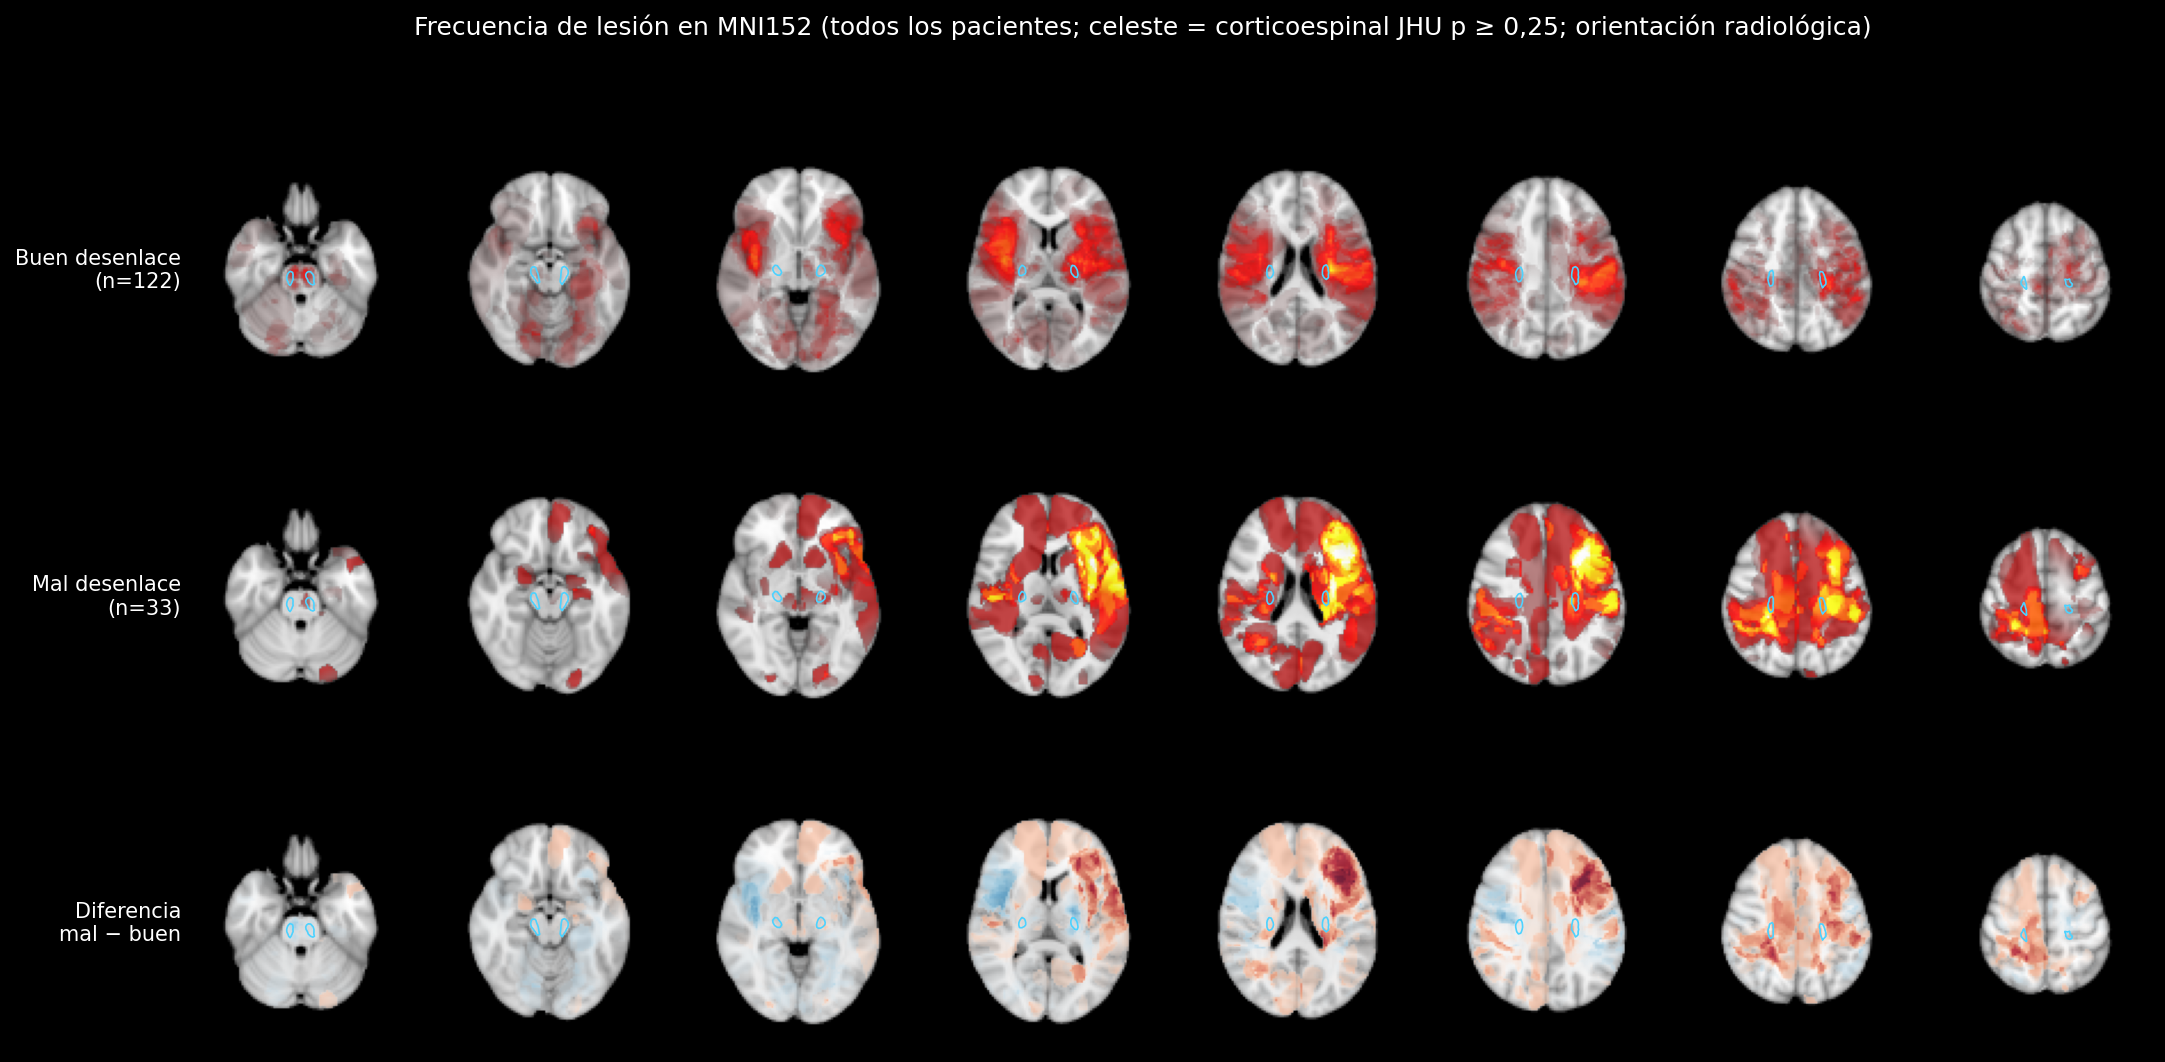

In [5]:
!"{PY}" 08_desconexion/desconexion.py
display(Image(filename="08_desconexion/resultados/mapa_frecuencia_mni.png", width=900))

## [6] Tractotron (BCB Toolkit, 68 tractos) cruzado con `dataset_report.csv`

`parsear_log.py` reconstruye las tablas de probabilidad y proporción de desconexión desde el log de ejecución de Tractotron. `analizar.py` las cruza con la tabla limpia y con territorio, tratamiento, volumen y mRS a 90 días.

In [6]:
!"{PY}" 09_tractotron/parsear_log.py "{LOG_TRACTOTRON}"
!"{PY}" 09_tractotron/analizar.py "{REPORTE}"

corridas: [1]
  corrida 1: 160 pacientes, 68 tractos
pacientes únicos: 160 | tractos: 68
tractos: Anterior_Commissure, Anterior_Thalamic_Projections_Left, Anterior_Thalamic_Projections_Right, Arcuate_Anterior_Segment_Left, Arcuate_Anterior_Segment_Right, Arcuate_Long_Segment_Left, Arcuate_Long_Segment_Right, Arcuate_Posterior_Segment_Left, Arcuate_Posterior_Segment_Right, Cingulum_Left, Cingulum_Left_anterior, Cingulum_Left_posterior, Cingulum_Right, Cingulum_Right_Anterior, Cingulum_Right_Posterior, Corpus_callosum, Cortico_Spinal_Left, Cortico_Spinal_Right, Face_U_tract_Left, Face_U_tract_Right, Fornix, Frontal_Aslant_Tract_Left, Frontal_Aslant_tract_Right, Frontal_Commissural, Frontal_Inferior_longitudinal_Left, Frontal_Inferior_longitudinal_Right, Frontal_Orbito_Polar_Left, Frontal_Orbito_Polar_Right, Frontal_Superior_Longitudinal_Left, Frontal_Superior_Longitudinal_Right, Fronto_Insular_tract1_Left, Fronto_Insular_tract1_Right, Fronto_Insular_tract2_Left, Fronto_Insular_tract2_Rig

Pacientes analizables: 155 (33 mal desenlace); sin Tractotron: 0

=== 1. CONTROL DE CALIDAD (Tractotron vs nuestro registro / reporte) ===
  pacientes con lesión que no toca ningún tracto (prob máx = 0): 16 | volumen mediano de ellos 0.00 mL
  CST: proporción Tractotron (BCB) vs fracción JHU de nuestro registro: rho = 0.56 (n=155)
  volumen: reporte vs nuestra máscara en MNI: rho = 0.92
  lateralidad del reporte vs hemisferio con más tractos desconectados (Tractotron):
col_0       der  izq
    laterality          
    1            48    9
    1,2           0    3
    2             4   65

=== 2. VALIDEZ CLÍNICA ===
  NIHSS mediano: CST intacto 3 (n=40) | CST desconectado 6 (n=115) | p = 7.8e-04
  nº de tractos desconectados vs NIHSS: rho = 0.27 (p = 7.9e-04)
  nº de tractos desconectados vs volumen: rho = 0.73
  mediana de tractos desconectados: buen 10 | mal 13 | p = 5.0e-02 | AUC solo 0.611

=== 3. TRACTO POR TRACTO (desconectado = prob > 0.5; solo tractos desconectados en ≥ 8 pacien

In [7]:
t = pd.read_csv("09_tractotron/resultados/tractos_vs_desenlace.csv")
t.head(10).round(3)

,tracto,n_desc,desc_buen,desc_mal,OR,p_fisher,p_ajust_edad_nihss,q_fisher,q_ajust
0,Fronto_Insular_tract4_Right,21,0.107,0.242,2.683,0.080,0.037,0.821,0.714
1,Arcuate_Anterior_Segment_Left,27,0.180,0.152,0.812,0.801,0.076,0.948,0.714
2,Arcuate_Long_Segment_Right,28,0.156,0.273,2.033,0.132,0.086,0.821,0.714
3,Handsup_U_tract_Right,13,0.066,0.152,2.545,0.152,0.103,0.821,0.714
4,Uncinate_Right,10,0.057,0.091,1.643,0.445,0.106,0.821,0.714
5,Arcuate_Long_Segment_Left,42,0.262,0.303,1.223,0.662,0.140,0.893,0.714
6,Arcuate_Posterior_Segment_Left,18,0.107,0.152,1.497,0.540,0.161,0.821,0.714
7,Fronto_Insular_tract3_Right,17,0.098,0.152,1.637,0.362,0.162,0.821,0.714
8,Fronto_Insular_tract5_Right,25,0.139,0.242,1.976,0.183,0.173,0.821,0.714
9,Arcuate_Anterior_Segment_Right,28,0.164,0.242,1.632,0.313,0.174,0.821,0.714


## [7] Síntesis: ¿qué agrega cada medida de la lesión a edad + NIHSS?

Valores tomados de las salidas de las celdas [4]–[6] (validación cruzada repetida; referencia edad + NIHSS = 0,823 con 155 pacientes y 33 eventos; las filas de ubicación usan solo train, referencia 0,789).

,variable agregada,fuente,ΔAUC
0,Volumen de lesión,Tractotron / reporte,-0.009
1,Región profunda (solo train),Ubicación [4],-0.023
2,6 regiones (solo train),Ubicación [4],-0.080
3,Carga corticoespinal (wCST-LL),JHU [5],-0.020
4,Perfil de 11 tractos,JHU [5],-0.027
5,Nº de tractos desconectados,Tractotron [6],-0.009
6,Perfil de 68 tractos,Tractotron [6],-0.150
7,"Trombectomía (tratamiento, no imagen)",dataset_report [6],0.009


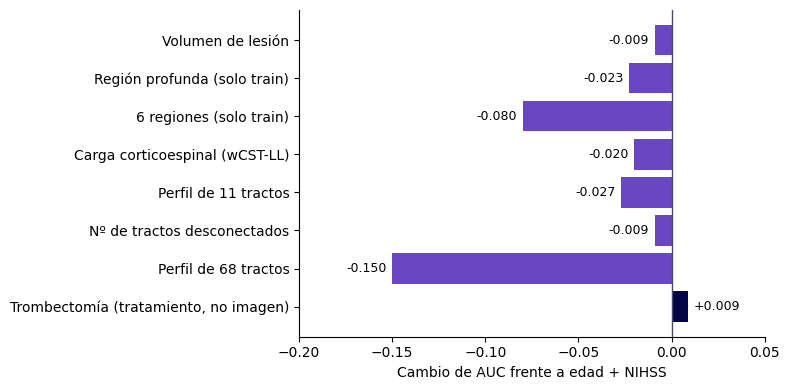

In [8]:
import matplotlib.pyplot as plt

sintesis = pd.DataFrame([
    ("Volumen de lesión",                          "Tractotron / reporte", -0.009),
    ("Región profunda (solo train)",               "Ubicación [4]",        -0.023),
    ("6 regiones (solo train)",                    "Ubicación [4]",        -0.080),
    ("Carga corticoespinal (wCST-LL)",             "JHU [5]",              -0.020),
    ("Perfil de 11 tractos",                       "JHU [5]",              -0.027),
    ("Nº de tractos desconectados",                "Tractotron [6]",       -0.009),
    ("Perfil de 68 tractos",                       "Tractotron [6]",       -0.150),
    ("Trombectomía (tratamiento, no imagen)",      "dataset_report [6]",   +0.009),
], columns=["variable agregada", "fuente", "ΔAUC"])
display(sintesis)

fig, ax = plt.subplots(figsize=(8, 4))
s = sintesis.iloc[::-1]
ax.barh(s["variable agregada"], s["ΔAUC"], color=["#040544" if v > 0 else "#6A47C2" for v in s["ΔAUC"]])
ax.axvline(0, color="#4A4A6E", lw=1)
for y, v in enumerate(s["ΔAUC"]):
    ax.text(v + (0.003 if v > 0 else -0.003), y, f"{v:+.3f}", va="center", ha="left" if v > 0 else "right", fontsize=9)
ax.set_xlim(-0.2, 0.05)
ax.set_xlabel("Cambio de AUC frente a edad + NIHSS")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Conclusión

Ninguna forma de medir la lesión (fusión profunda, ubicación, carga corticoespinal, perfiles de tractos) mejora a **edad + NIHSS** para el mRS al egreso con esta muestra (155 pacientes, 33 eventos). Los controles lo explican: con la imagen barajada la fusión da el mismo AUC y la compuerta le asigna a la imagen solo 9–15 % del peso. El NIHSS ya mide el efecto clínico de la lesión. Corregir un error de digitación (NIHSS = 120) movió más el AUC (+0,05) que cualquier variable de imagen.